# AI6101 Reinforcement Learning Assignment: CliffBoxPushing

**Algorithm:** tabular Q-learning (off-policy TD control), with a noise-aware extension for the action-noise study.

**Notebook contents**
1. Environment (provided, unmodified) and random-agent baseline
2. Q-learning agent (`RLAgent`) and training on the original dense reward
3. Learning curves and an ablation against the template's default hyper-parameters
4. Final V-table and policy visualisation (all agent positions for each box position along the solved path)
5. Action-noise robustness study (train $p_{train}\in\{0,0.1,0.2\}$, test $p_{test}\in\{0,0.1,0.2\}$)
6. **Bonus 1:** comparison of exploration strategies (no exploration, ε-greedy, decaying ε-greedy, UCB, Boltzmann)
7. **Bonus 2:** sparse-reward version (reward only +1000 at the goal)

**What was changed:** nothing in the game setting. The map, `step()`, `reset()` and the reward function are untouched.
All changes live in the agent and the training / evaluation loops, and are justified by ablations below.



In [1]:
from typing import List, Tuple
import copy
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
%matplotlib inline

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
# Compatibility: NumPy >= 2.x no longer exposes np.chararray at the top level (the provided renderer uses it).
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)
if not hasattr(np, 'chararray'):
    np.chararray = np.char.chararray

ACTION_NAMES = {1: 'up', 2: 'down', 3: 'left', 4: 'right'}
ACTION_ARROWS = {1: '↑', 2: '↓', 3: '←', 4: '→'}

## 1. Environment (provided, unmodified)

The grid world looks like:

```
____________________________________________________________
|___|_0_|_1_|_2_|_3_|_4_|_5_|_6_|_7_|_8_|_9_|_10|_11|_12|_13|
|_0_|___|___|___|_x_|___|___|___|___|___|___|___|_x_|_x_|___|
|_1_|___|_B_|___|_x_|___|___|___|___|___|___|___|___|___|___|
|_2_|___|___|___|_x_|___|___|___|_x_|___|___|___|___|___|___|
|_3_|___|___|___|_x_|___|___|___|_x_|___|___|___|_x_|_x_|___|
|_4_|___|_A_|___|___|___|___|_x_|___|___|___|___|_x_|_x_|_G_|
|_5_|___|___|___|_x_|___|___|_x_|___|___|___|___|_x_|___|___|
```

Observations about the provided code that shape the design of the agent:

* **State format.** `reset()` / `step()` return a flat tuple `(agent_row, agent_col, box_row, box_col)`, so there are $6\cdot14\cdot6\cdot14 = 7056$ table entries.
* **Reward scale.** Every step costs $-1 - d(\text{agent},\text{box}) - d(\text{box},\text{goal})$, typically −15 to −20. A 100-step episode that never succeeds therefore scores about −1500 to −2000, which is *worse* than jumping into a cliff on step 1 (≈ −1016). A learner that has never found the goal is pulled towards an early-suicide policy. Section 6 shows this trap empirically.
* **Time limit.** `done` becomes `True` after 100 steps, but time is not part of the state. Therefore treat a timeout as a truncation (keep bootstrapping), and only cliff and goal as true terminal states.
* **Box movement limits.** `box_hard_boundary` stops the box entering row 0, row 5 or column 0. Together with the cliffs this leaves a narrow route: the box must enter column 13 at row 1 or 2 and then be pushed *down* into the goal at (4, 13).

In [2]:
AGENT = 'A'
BOX = 'B'
GOAL = 'G'
DANGER = 'x'
GRID = '_'


class CliffBoxGridWorld:
    """
    Cliff Box Pushing Grid World.
    """
    action_space = [1, 2, 3, 4]
    forces = {
        1: np.array([-1, 0]),
        2: np.array([1,  0]),
        3: np.array([0, -1]),
        4: np.array([0,  1]),
    }
    world_width = 14
    world_height = 6
    goal_pos = np.array([4, 13])
    init_agent_pos = np.array([4, 1])
    init_box_pos = np.array([1, 1])
    danger_region = [
        [(0, 3), (3, 3)],
        [(5, 3), (5, 3)],
        [(4, 6), (5, 6)],
        [(2, 7), (3, 7)],
        [(0, 11), (0, 11)],
        [(3, 11), (5, 11)],
        [(0, 12), (0, 12)],
        [(3, 12), (4, 12)],
    ]

    def __init__(self,
                 episode_length=100,
                 render=False,
                 ):
        """
        The grid world looks like:
        ____________________________________________________________
        |___|_0_|_1_|_2_|_3_|_4_|_5_|_6_|_7_|_8_|_9_|_10|_11|_12|_13|
        |_0_|___|___|___|_x_|___|___|___|___|___|___|___|_x_|_x_|___|
        |_1_|___|_B_|___|_x_|___|___|___|___|___|___|___|___|___|___|
        |_2_|___|___|___|_x_|___|___|___|_x_|___|___|___|___|___|___|
        |_3_|___|___|___|_x_|___|___|___|_x_|___|___|___|_x_|_x_|___|
        |_4_|___|_A_|___|___|___|___|_x_|___|___|___|___|_x_|_x_|_G_|
        |_5_|___|___|___|_x_|___|___|_x_|___|___|___|___|_x_|___|___|
        """
        # Environment configurations.
        self.episode_length = episode_length
        self.render = render
        self.agent_pos = self.init_agent_pos
        self.box_pos = self.init_box_pos

        # Visualization.
        if self.render:
            self.world = np.chararray((self.world_height, self.world_width))
            self.last_agent_pos = copy.deepcopy(self.agent_pos)
            self.last_box_pos = copy.deepcopy(self.box_pos)
            self.world[:] = GRID
            for region in self.danger_region:
                A, B = region
                assert A[1] == B[1], "A[1] != B[1]"
                self.world[A[0]:B[0]+1, A[1]] = DANGER
            self.world[self.agent_pos[0], self.agent_pos[1]] = AGENT
            self.world[self.box_pos[0], self.box_pos[1]] = BOX
            self.world[self.goal_pos[0], self.goal_pos[1]] = GOAL

    def reset(self):
        """
        Resets the environment.

        Returns:
            The initial state (agent position and box position).
        """
        self.timesteps = 0
        self.action_history = []
        self.agent_pos = self.init_agent_pos
        self.box_pos = self.init_box_pos

        return tuple([*self.agent_pos.tolist(), *self.box_pos.tolist()])

    def step(self, actions: int):
        """ 
        Args: actions (a list of int).

        Returns:
            The next state, reward, done, info.
        """
        self.action_history.append(actions)

        # Update the state.
        force = self.forces[actions]
        # check if the agent is near the box
        if np.sum(np.abs(self.agent_pos - self.box_pos)) == 1:
            # check if box is moved
            if all(self.agent_pos + force == self.box_pos):
                # check out of boundary
                self.box_pos = self._check_pos_boundary(pos=self.box_pos + force, box_hard_boundary=True)
        # move the agent
        new_agent_pos = self._check_pos_boundary(self.agent_pos + force)
        if not all(new_agent_pos == self.box_pos):
            self.agent_pos = new_agent_pos
        state = tuple([*self.agent_pos.tolist(), *self.box_pos.tolist()])

        # Calculate the rewards
        done = self.timesteps == self.episode_length - 1
        # the distance between agents and box
        dist = np.sum(np.abs(self.agent_pos - self.box_pos))
        reward = -1  # -1 for each step
        reward -= dist
        # if agents or box is off the cliff
        if self._check_off_cliff(self.agent_pos) or self._check_off_cliff(self.box_pos):
            reward += -1000
            done = True
        
        if all(self.box_pos == self.goal_pos):
            reward += 1000
            done = True
        
        reward -= np.sum(np.abs(self.box_pos - self.goal_pos))

        if self.render:
            self._update_render()

        self.timesteps += 1
        info = {}

        return state, reward, done, info

    def print_world(self):
        """
        Render the world in the command line.
        """
        if len(self.action_history) > 0:
            print(f'Action: {self.action_history[-1]}')
        print(self.world)

    def _check_pos_boundary(self, pos, box_hard_boundary: bool = False):
        """
        Move the given position within the world bound.
        """
        if pos[0] < 0:
            pos[0] = 0
        if pos[0] >= self.world_height:
            pos[0] = self.world_height - 1
        if pos[1] < 0:
            pos[1] = 0
        if pos[1] >= self.world_width:
            pos[1] = self.world_width - 1
        
        if box_hard_boundary:
            if pos[0] == 0:
                pos[0] += 1
            elif pos[0] == self.world_height - 1:
                pos[0] = self.world_height - 2
            if pos[1] == 0:
                pos[1] += 1
                    
        return pos

    def _check_off_cliff(self, pos):
        """
        Check if the given position is off cliff.
        """
        for region in self.danger_region:
            A, B = region
            assert A[1] == B[1], "A[1] != B[1]"
            if A[0] <= pos[0] <= B[0] and pos[1] == A[1]:
                return True
        return False

    def _update_render(self):
        """
        Update the render information.
        """
        if not all(self.last_agent_pos == self.agent_pos):
                pos = self.last_agent_pos
                if (pos[0] != self.goal_pos[0]) or (pos[1] != self.goal_pos[1]):
                    self.world[pos[0], pos[1]] = GRID

        if not all(self.last_box_pos == self.box_pos):
            pos = self.last_box_pos
            if self.world[pos[0], pos[1]].decode('UTF-8') not in {AGENT}:
                self.world[pos[0], pos[1]] = GRID

        if (self.agent_pos[0] != self.goal_pos[0]) or (self.agent_pos[1] != self.goal_pos[1]):
            self.world[self.agent_pos[0], self.agent_pos[1]] = AGENT
        self.world[self.box_pos[0], self.box_pos[1]] = BOX
        self.last_box_pos = copy.deepcopy(self.box_pos)
        self.last_agent_pos = copy.deepcopy(self.agent_pos)

Helper functions used throughout (they only *read* the environment's state, they never change it):

In [3]:
def reached_goal(env) -> bool:
    # True if the box is on the goal cell.
    return bool(np.all(env.box_pos == env.goal_pos))

def fell_off_cliff(env) -> bool:
    # True if the agent or the box is on a cliff cell.
    return bool(env._check_off_cliff(env.agent_pos) or env._check_off_cliff(env.box_pos))

def apply_action_noise(action, p, action_space=(1, 2, 3, 4)):
    # With probability p, replace the action by one of the OTHER three actions (uniformly); otherwise keep it.
    if p > 0 and np.random.uniform(0, 1) < p:
        others = [a for a in action_space if a != action]
        return others[np.random.randint(len(others))]
    return action

def moving_average(x, window=200):
    # Trailing moving average (shorter window at the start) for smoothing learning curves.
    x = np.asarray(x, dtype=float)
    c = np.cumsum(np.insert(x, 0, 0.0))
    out = np.empty_like(x)
    for i in range(len(x)):
        lo = max(0, i + 1 - window)
        out[i] = (c[i + 1] - c[lo]) / (i + 1 - lo)
    return out

Here is the example random agent class (provided):

In [4]:
class RandomAgent:
    def __init__(self, env, num_episodes):
        self.action_space = [1, 2, 3, 4]
        self.env = env
        self.num_episodes = num_episodes

    def act(self):
        """Returns a random choice of the available actions"""
        return np.random.choice(self.action_space)

    def learn(self):
        rewards = []
        
        for _ in range(self.num_episodes):
            cumulative_reward = 0 # Initialise values of each game
            state = self.env.reset()
            done = False
            while not done: # Run until game terminated
                action = self.act() 
                next_state, reward, done, info = self.env.step(action)
                cumulative_reward += reward
                state = next_state
            rewards.append(cumulative_reward)

        return rewards

## 2. The Q-learning agent

**Q-learning** learns the optimal action-value function $Q^*(s,a)$ from experience with the off-policy TD update

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[r + \gamma\,\max_{a'} Q(s',a') - Q(s,a)\Big],$$

where the bootstrap term is dropped ($\gamma\max Q(s',\cdot)=0$) only when $s'$ is a *true* terminal state (cliff or goal). The behaviour policy is ε-greedy with a decaying ε. The greedy policy is $\pi(s)=\arg\max_a Q(s,a)$ and the state value is $V(s)=\max_a Q(s,a)$.

**Design choices** (each is backed by an experiment later in the notebook):

| Choice | Setting | Why |
|---|---|---|
| Learning rate α | 0.5 (main), 0.3 (noisy) | Dynamics are deterministic without noise, so large steps are safe; a smaller α averages noisy transitions. |
| Exploration | ε from 0.2 decaying ×0.9995 per episode, floor 0.01 | Constant ε = 0.1 keeps pushing the box into cliffs late in training (Section 3 ablation). |
| Q initialisation | 0 | All true returns are negative, so 0 is *optimistic*: untried actions look better than tried ones, which drives systematic exploration (Bonus 1). |
| Timeouts | bootstrap (not terminal) | Time is not in the state; treating timeouts as terminal would bias values towards 0. |

**Action noise.** With probability $p$ the *selected* action $a$ is replaced by a uniformly random other action $\tilde a$ before `env.step()`. From the agent's point of view this makes the transition stochastic. Two update rules are possible:

* **Vanilla Q-learning:** update $Q(s,a)$ for the *selected* action with the observed outcome. This is correct in expectation but has high variance, because the same $(s,a)$ sometimes receives a −1000 cliff outcome caused by a different action.
* **Noise-aware Q-learning (our extension, `noise_aware=True`):** the noise model is known (we inject it ourselves), so we learn $Q_{det}(s,\tilde a)$ for the action that was *actually executed* (a deterministic, low-variance target) and act on the expected value of choosing $a$ under noise:
$$Q_p(s,a) = (1-p)\,Q_{det}(s,a) + \tfrac{p}{3}\sum_{b\neq a} Q_{det}(s,b), \qquad Q_{det}(s,\tilde a) \leftarrow Q_{det}(s,\tilde a) + \alpha\big[r + \gamma \max_{a'} Q_p(s',a') - Q_{det}(s,\tilde a)\big].$$
This is the same fixed point as Q-learning on the noisy MDP (the Bellman optimality equation of the noisy MDP), but each update uses a single deterministic transition. With $p=0$ it reduces exactly to standard Q-learning. Section 5 compares both rules.

In [5]:
class RLAgent:
    """Tabular Q-learning agent for CliffBoxGridWorld.

    Extra options (all default to plain Q-learning with decaying epsilon-greedy):
      exploration : 'epsilon_greedy' | 'greedy' | 'ucb' | 'boltzmann'
      noise_aware : learn Q for the executed action and act on expected value under the known action noise
      q_init      : initial Q-value (0 is optimistic for the dense reward; 1000 is optimistic for the sparse one)
      sparse_reward : train on +1000 at the goal and 0 otherwise (Bonus 2). The episode return that is
                      recorded and plotted is always the ORIGINAL environment reward, so curves are comparable.
      count_bonus : beta for an intrinsic exploration bonus beta / sqrt(N(s')) (Bonus 2 comparison)
    """

    def __init__(self, env, num_episodes, epsilon=0.2, alpha=0.5, gamma=0.99,
                 epsilon_decay=0.9995, epsilon_min=0.01, exploration='epsilon_greedy',
                 ucb_c=20.0, temperature=20.0, q_init=0.0, noise_aware=True,
                 sparse_reward=False, count_bonus=0.0, seed=None):
        self.action_space = env.action_space
        self.q_table = dict()          # Q-values: state -> {action: value}
        self.action_counts = dict()    # N(s, a), used by UCB
        self.state_visits = dict()     # N(s), used for the count bonus and to mask unvisited states in plots
        # Loop through all possible grid spaces, create a sub-dictionary for each
        for agent_x in range(env.world_height):
            for agent_y in range(env.world_width):
                for box_x in range(env.world_height):
                    for box_y in range(env.world_width):
                        s = (agent_x, agent_y, box_x, box_y)
                        self.q_table[s] = {k: float(q_init) for k in self.action_space}
                        self.action_counts[s] = {k: 0 for k in self.action_space}
                        self.state_visits[s] = 0

        self.env = env
        self.num_episodes = num_episodes
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.alpha = alpha
        self.gamma = gamma
        self.exploration = exploration
        self.ucb_c = ucb_c
        self.temperature = temperature
        self.noise_aware = noise_aware
        self.sparse_reward = sparse_reward
        self.count_bonus = count_bonus
        self.seed = seed
        self.train_noise = 0.0          # action-noise level used in training (set by learn)
        self.successes = []             # per-episode: did the box reach the goal?
        self.episode_lengths = []

    # ------------------------------------------------------------------ acting
    def action_values(self, state):
        """Values used for acting. Under noise-aware learning, the expected value of
        choosing each action given the training noise level p; otherwise plain Q(s, .)."""
        q = self.q_table[state]
        p = self.train_noise
        if self.noise_aware and p > 0:
            total = sum(q.values())
            return {a: (1 - p) * q[a] + (p / 3.0) * (total - q[a]) for a in q}
        return q

    def _greedy(self, values):
        max_value = max(values.values())
        best = [k for k, v in values.items() if v == max_value]
        return best[np.random.randint(len(best))]   # random tie-breaking

    def act(self, state, is_training=True):
        """Returns the action from the exploration strategy (training) or the greedy action (evaluation)."""
        values = self.action_values(state)
        if not is_training or self.exploration == 'greedy':
            return self._greedy(values)

        if self.exploration == 'epsilon_greedy':
            if np.random.uniform(0, 1) < self.epsilon:
                return self.action_space[np.random.randint(len(self.action_space))]
            return self._greedy(values)

        if self.exploration == 'ucb':
            counts = self.action_counts[state]
            untried = [a for a in self.action_space if counts[a] == 0]
            if untried:                                   # try every action once first
                return untried[np.random.randint(len(untried))]
            log_n = np.log(sum(counts.values()))
            scores = {a: values[a] + self.ucb_c * np.sqrt(log_n / counts[a]) for a in self.action_space}
            return self._greedy(scores)

        if self.exploration == 'boltzmann':
            v = np.array([values[a] for a in self.action_space])
            z = np.exp((v - v.max()) / self.temperature)
            return self.action_space[np.random.choice(len(v), p=z / z.sum())]

        raise ValueError(self.exploration)

    # ------------------------------------------------------------------ learning
    def learn(self, action_noise=0.0):
        """Updates Q-values iteratively. Returns the list of (original-reward) episode returns."""
        if self.seed is not None:
            np.random.seed(self.seed)
        self.train_noise = action_noise
        rewards = []
        self.successes, self.episode_lengths = [], []

        for _ in range(self.num_episodes):
            cumulative_reward = 0   # Initialise values of each game
            state = self.env.reset()
            done = False
            steps = 0
            while not done:   # Run until game terminated
                # 1) choose an action with the exploration strategy
                action = self.act(state)
                # 2) robustness study: with prob. p, the executed action is a random OTHER action
                executed = apply_action_noise(action, action_noise, self.action_space)
                # 3) interact with the (unmodified) environment
                next_state, reward, done, info = self.env.step(executed)
                cumulative_reward += reward
                steps += 1

                # 4) work out whether next_state is a TRUE terminal (cliff/goal) or just a timeout
                goal = reached_goal(self.env)
                terminal = goal or fell_off_cliff(self.env)

                train_reward = reward
                if self.sparse_reward:          # Bonus 2: only +1000 at the goal
                    train_reward = 1000.0 if goal else 0.0
                self.state_visits[next_state] += 1
                if self.count_bonus > 0:        # optional intrinsic exploration bonus
                    train_reward += self.count_bonus / np.sqrt(self.state_visits[next_state])

                # 5) TD target
                if self.noise_aware and action_noise > 0:
                    update_action = executed    # deterministic transition of the executed action
                    bootstrap = max(self.action_values(next_state).values())
                else:
                    update_action = action      # standard Q-learning credits the selected action
                    bootstrap = max(self.q_table[next_state].values())
                target = train_reward if terminal else train_reward + self.gamma * bootstrap

                # 6) Q-learning update
                q_sa = self.q_table[state][update_action]
                self.q_table[state][update_action] = q_sa + self.alpha * (target - q_sa)
                self.action_counts[state][action] += 1

                state = next_state

            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)
            rewards.append(cumulative_reward)
            self.successes.append(goal)
            self.episode_lengths.append(steps)

        return rewards

### Game interface

The original cell asks for keyboard input, which blocks automatic execution. Set `MANUAL_PLAY = True` to play by hand; by default a short scripted sequence demonstrates the push mechanics.

In [6]:
MANUAL_PLAY = False   # set True to control the agent with keyboard input

env = CliffBoxGridWorld(render=True)
env.reset()
env.print_world()
done = False
rewards = []

if MANUAL_PLAY:
    while not done:
        action = int(input("Please input the actions (up: 1, down: 2, left: 3, right: 4): "))
        state, reward, done, info = env.step(action)
        rewards.append(reward)
        print(f'step: {env.timesteps}, state: {state}, actions: {action}, reward: {reward}')
        env.print_world()
else:
    # Scripted demo: walk next to the box, then try to push it left into column 0.
    # The box cannot enter column 0 (box_hard_boundary), so neither the box nor the agent moves on the last step.
    for action in [1, 1, 4, 1, 3]:
        state, reward, done, info = env.step(action)
        rewards.append(reward)
        print(f'step: {env.timesteps}, state: {state}, actions: {action}, reward: {reward}')
    env.print_world()

print(f'rewards: {sum(rewards)}')
print(f'action history: {env.action_history}')

[[b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'x' b'x' b'_']
 [b'_' b'B' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'x' b'_']
 [b'_' b'A' b'_' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'x' b'x' b'G']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'x' b'_' b'_']]
step: 1, state: (3, 1, 1, 1), actions: 1, reward: -18
step: 2, state: (2, 1, 1, 1), actions: 1, reward: -17
step: 3, state: (2, 2, 1, 1), actions: 4, reward: -18
step: 4, state: (1, 2, 1, 1), actions: 1, reward: -17
step: 5, state: (1, 2, 1, 1), actions: 3, reward: -17
Action: 3
[[b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'x' b'x' b'_']
 [b'_' b'B' b'A' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' 

Random-agent baseline (provided):

Random agent: mean return -1394.9, best -1057.0


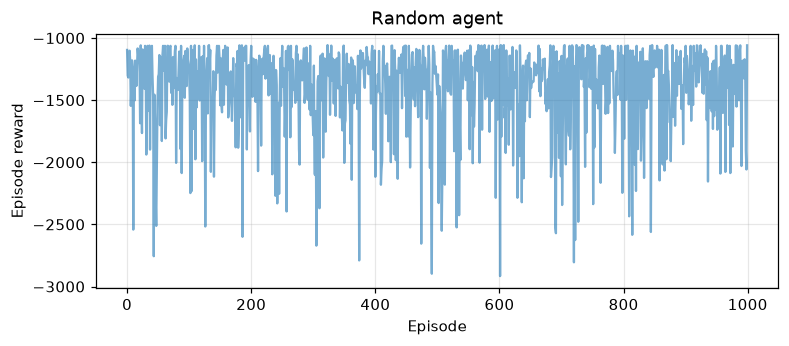

In [7]:
np.random.seed(0)
env = CliffBoxGridWorld()
random_agent = RandomAgent(env, num_episodes=1000)
random_rewards = random_agent.learn()
print(f"Random agent: mean return {np.mean(random_rewards):.1f}, best {np.max(random_rewards):.1f}")

plt.figure(figsize=(8, 3))
plt.plot(random_rewards, alpha=0.6)
plt.xlabel('Episode'); plt.ylabel('Episode reward'); plt.title('Random agent')
plt.show()

## 3. Train the Q-learning agent

Success is measured as *the box reached the goal*, not "episode return > 0". With the dense reward, a long but successful episode can still have a negative sum, so the template's `rewards > 0` test would under-count successes.

Training time: 66.5s
First successful episode: 3006
Training success rate (last 2000 episodes, with exploration): 0.949
Mean return (last 2000 episodes): 476.6


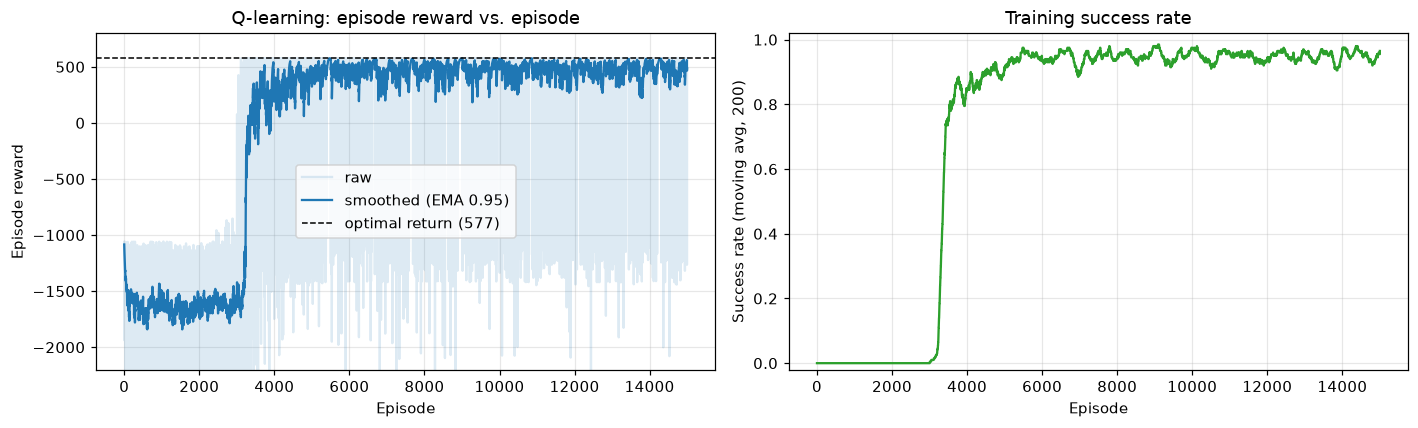

In [8]:
t0 = time.time()
env = CliffBoxGridWorld()
agent = RLAgent(env, num_episodes=15000, epsilon=0.2, alpha=0.5, gamma=0.99,
                epsilon_decay=0.9995, epsilon_min=0.01, seed=0)
rewards = agent.learn()
print(f"Training time: {time.time() - t0:.1f}s")

successes = np.array(agent.successes)
first_success = int(np.argmax(successes)) if successes.any() else None
print(f"First successful episode: {first_success}")
print(f"Training success rate (last 2000 episodes, with exploration): {successes[-2000:].mean():.3f}")
print(f"Mean return (last 2000 episodes): {np.mean(rewards[-2000:]):.1f}")

# Smooth plot (same exponential smoothing as the template)
weight = 0.95
last = rewards[0]
smoothed = []
for v in rewards:
    smoothed_val = last * weight + (1 - weight) * v
    smoothed.append(smoothed_val)
    last = smoothed_val

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(rewards, color='tab:blue', alpha=0.15, label='raw')
axes[0].plot(smoothed, color='tab:blue', label='smoothed (EMA 0.95)')
axes[0].axhline(577, color='k', ls='--', lw=1, label='optimal return (577)')
axes[0].set_ylim(-2200, 800)
axes[0].set_xlabel('Episode'); axes[0].set_ylabel('Episode reward')
axes[0].set_title('Q-learning: episode reward vs. episode'); axes[0].legend()
axes[1].plot(moving_average(successes, 200), color='tab:green')
axes[1].set_xlabel('Episode'); axes[1].set_ylabel('Success rate (moving avg, 200)')
axes[1].set_title('Training success rate'); axes[1].set_ylim(-0.02, 1.02)
plt.tight_layout(); plt.show()

### Ablation: template defaults vs. tuned hyper-parameters

The template's defaults are constant ε = 0.1 and α = 0.1. We train that configuration with the same budget and seed to justify the changes.

Training time: 78.6s
Template defaults (eps=0.1, alpha=0.1) first success:   6977 | train success (last 2000): 0.581 | mean return (last 2000):   -244.4
Tuned (eps 0.2 decaying, alpha=0.5)    first success:   3006 | train success (last 2000): 0.949 | mean return (last 2000):    476.6


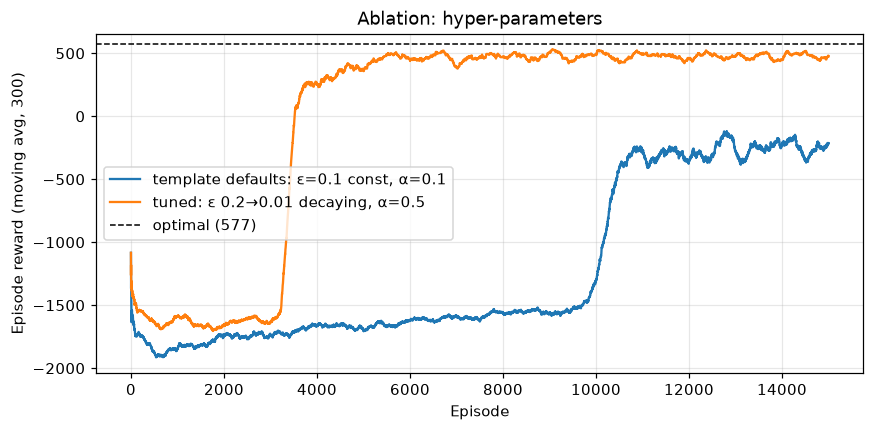

In [9]:
t0 = time.time()
env = CliffBoxGridWorld()
baseline_agent = RLAgent(env, num_episodes=15000, epsilon=0.1, alpha=0.1, gamma=0.99,
                         epsilon_decay=1.0, epsilon_min=0.1, seed=0)
baseline_rewards = baseline_agent.learn()
print(f"Training time: {time.time() - t0:.1f}s")

def summarise(name, a, r):
    s = np.array(a.successes)
    first = int(np.argmax(s)) if s.any() else None
    print(f"{name:<38} first success: {str(first):>6} | train success (last 2000): {s[-2000:].mean():.3f}"
          f" | mean return (last 2000): {np.mean(r[-2000:]):8.1f}")

summarise('Template defaults (eps=0.1, alpha=0.1)', baseline_agent, baseline_rewards)
summarise('Tuned (eps 0.2 decaying, alpha=0.5)', agent, rewards)

plt.figure(figsize=(9, 4))
plt.plot(moving_average(baseline_rewards, 300), label='template defaults: ε=0.1 const, α=0.1')
plt.plot(moving_average(rewards, 300), label='tuned: ε 0.2→0.01 decaying, α=0.5')
plt.axhline(577, color='k', ls='--', lw=1, label='optimal (577)')
plt.xlabel('Episode'); plt.ylabel('Episode reward (moving avg, 300)')
plt.title('Ablation: hyper-parameters'); plt.legend(); plt.show()

**Ablation result.** With the template defaults, the goal is first reached at episode ~7000 and the training success rate stays at ~58%. Even after the agent knows the solution, a constant 10% of random actions keeps pushing the box (or the agent) into a cliff, because the solution path runs right next to cliffs. Decaying ε (0.2 → 0.01) and a larger learning rate (α = 0.5, safe because the dynamics are deterministic) find the goal more than twice as fast (~3000 episodes) and reach ~95% training success. The greedy policy of both agents is optimal, so the gain is in **sample efficiency and training-time performance**.

## 4. Final V-table and policy

$V(s) = \max_a Q(s,a)$ and $\pi(s) = \arg\max_a Q(s,a)$.

In [10]:
def visualize(q_table):
    v_table = {}
    policy = {}
    for key, v in q_table.items():
        v_table[key] = max(v.values())                       # V(s) = max_a Q(s, a)
        policy[key] = max(v, key=v.get)                      # pi(s) = argmax_a Q(s, a)
    state_num = len(q_table.keys())
    print(f"State space: {state_num}")

    # Print the largest 20 state values in v_table and the corresponding policy
    for k, val in sorted(v_table.items(), key=lambda x: x[1], reverse=True)[:20]:
      print("v_table", k, val / state_num)
      print("policy", k, policy[k], f"({ACTION_NAMES[policy[k]]})")
    return v_table, policy

v_table, policy = visualize(agent.q_table)

State space: 7056
v_table (2, 13, 3, 13) 0.14143990929705216
policy (2, 13, 3, 13) 2 (down)
v_table (1, 13, 2, 13) 0.1396003401360544
policy (1, 13, 2, 13) 2 (down)
v_table (1, 13, 3, 13) 0.1396003401198028
policy (1, 13, 3, 13) 2 (down)
v_table (2, 12, 3, 13) 0.13960033805267946
policy (2, 12, 3, 13) 4 (right)
v_table (1, 12, 2, 13) 0.13763744331065758
policy (1, 12, 2, 13) 4 (right)
v_table (0, 13, 2, 13) 0.13763744324643318
policy (0, 13, 2, 13) 2 (down)
v_table (2, 12, 2, 13) 0.13555245209750563
policy (2, 12, 2, 13) 1 (up)
v_table (1, 11, 2, 13) 0.13555245209725744
policy (1, 11, 2, 13) 4 (right)
v_table (2, 11, 2, 12) 0.1336300341524943
policy (2, 11, 2, 12) 4 (right)
v_table (2, 11, 2, 13) 0.1336300341524924
policy (2, 11, 2, 13) 4 (right)
v_table (2, 10, 2, 11) 0.131585117030924
policy (2, 10, 2, 11) 4 (right)
v_table (2, 10, 2, 12) 0.13158511703044026
policy (2, 10, 2, 12) 4 (right)
v_table (1, 11, 2, 12) 0.13158511052496508
policy (1, 11, 2, 12) 2 (down)
v_table (2, 9, 2, 10)

The top-20 printout only shows states next to the goal. Following the hint (*"consider all the agent positions and the box positions"*), the policy is a function of four coordinates. We visualise it by **fixing the box position** and drawing, for **every agent cell**, the value $V$ as a colour and the greedy action as an arrow. We do this for box positions along the greedy solution path.

* Black cells are cliffs. **B** is the box and **G** the goal.
* Grey cells are states never visited during training (their Q-values are still the initial 0 and carry no information).

Greedy rollout: success=True, return=577, steps=39
Actions: ↑ ↑ ← ↑ → ↑ → ↓ ↓ ↓ ← ↓ → → → ↓ → ↑ ↑ ↑ ← ↑ → → → → → ↑ → ↓ ← ↓ → → → ↑ → ↓ ↓


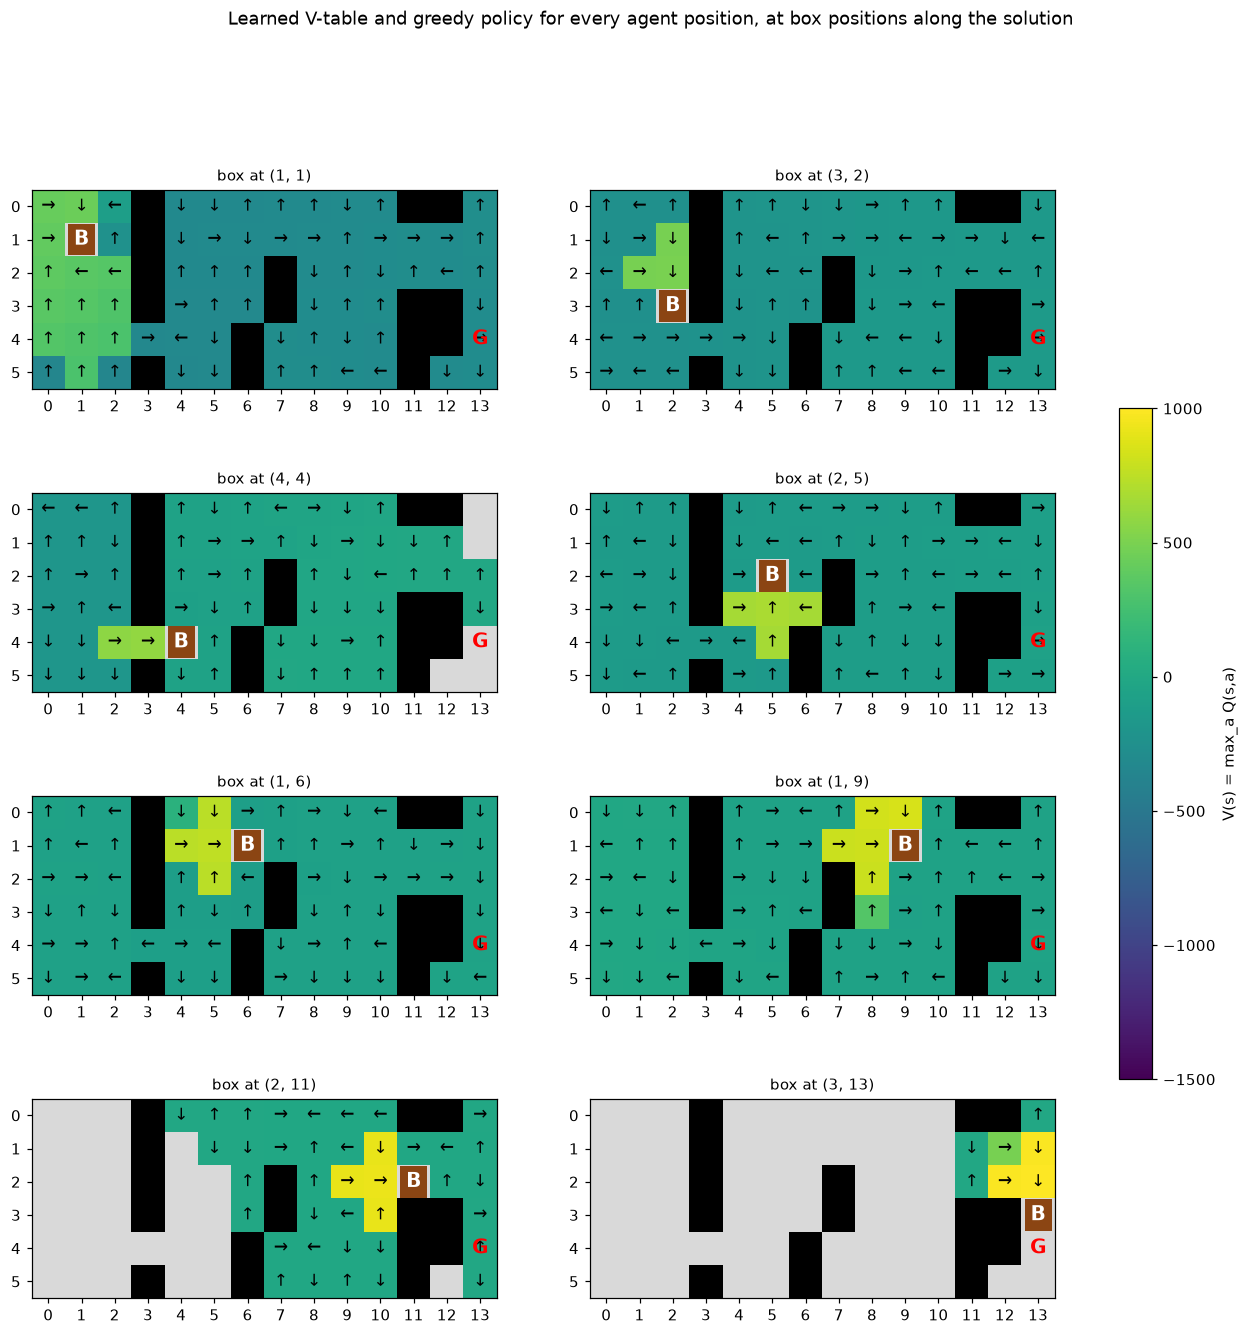

In [11]:
def greedy_rollout(agent, max_steps=100):
    # Run the greedy policy once in a fresh environment and return the visited states and actions.
    env = CliffBoxGridWorld()
    state = env.reset()
    states, actions, ret, done = [state], [], 0, False
    while not done:
        a = agent.act(state, is_training=False)
        state, r, done, _ = env.step(a)
        states.append(state); actions.append(a); ret += r
    return states, actions, ret, reached_goal(env)

def cliff_mask():
    m = np.zeros((CliffBoxGridWorld.world_height, CliffBoxGridWorld.world_width), dtype=bool)
    for (r0, c), (r1, _) in CliffBoxGridWorld.danger_region:
        m[r0:r1 + 1, c] = True
    return m

CLIFF = cliff_mask()

def plot_policy_for_box(agent, box_pos, ax, title=None, vmin=None, vmax=None):
    # Heatmap of V(agent, box fixed) with greedy arrows for every agent cell.
    H, W = CliffBoxGridWorld.world_height, CliffBoxGridWorld.world_width
    V = np.full((H, W), np.nan)
    for r in range(H):
        for c in range(W):
            s = (r, c, *box_pos)
            if CLIFF[r, c] or (r, c) == tuple(box_pos) or agent.state_visits[s] == 0:
                continue
            vals = agent.action_values(s)
            V[r, c] = max(vals.values())
            ax.text(c, r, ACTION_ARROWS[max(vals, key=vals.get)], ha='center', va='center', fontsize=11)
    cmap = plt.get_cmap('viridis').copy(); cmap.set_bad('#d9d9d9')
    im = ax.imshow(V, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.imshow(np.where(CLIFF, 1.0, np.nan), cmap=ListedColormap(['black']), vmin=0, vmax=1)
    gr, gc = CliffBoxGridWorld.goal_pos
    ax.text(gc, gr, 'G', ha='center', va='center', color='red', fontsize=13, fontweight='bold')
    ax.text(box_pos[1], box_pos[0], 'B', ha='center', va='center', color='white', fontsize=13, fontweight='bold',
            bbox=dict(boxstyle='square', fc='saddlebrown', ec='none'))
    ax.set_xticks(range(W)); ax.set_yticks(range(H)); ax.grid(False)
    ax.set_title(title or f'box at {tuple(box_pos)}', fontsize=10)
    return im

states, actions, ret, ok = greedy_rollout(agent)
print(f"Greedy rollout: success={ok}, return={ret}, steps={len(actions)}")
print("Actions:", ' '.join(ACTION_ARROWS[a] for a in actions))

# distinct box positions along the solution path, in order
box_path = []
for s in states:
    b = s[2:]
    if not box_path or box_path[-1] != b:
        box_path.append(b)
box_path = [b for b in box_path if b != tuple(CliffBoxGridWorld.goal_pos)]
idx = np.unique(np.linspace(0, len(box_path) - 1, 8).round().astype(int))
chosen = [box_path[i] for i in idx]

fig, axes = plt.subplots(int(np.ceil(len(chosen) / 2)), 2, figsize=(15, 3.3 * np.ceil(len(chosen) / 2)),
                         gridspec_kw=dict(hspace=0.45))
for ax, b in zip(axes.flat, chosen):
    im = plot_policy_for_box(agent, b, ax, vmin=-1500, vmax=1000)
for ax in list(axes.flat)[len(chosen):]:
    ax.axis('off')
fig.colorbar(im, ax=axes, shrink=0.6, label='V(s) = max_a Q(s,a)')
fig.suptitle('Learned V-table and greedy policy for every agent position, at box positions along the solution', y=1.0)
plt.show()

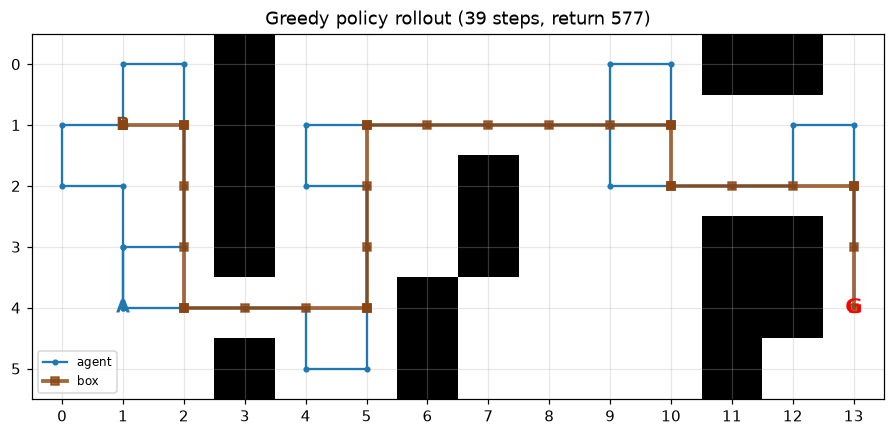

In [12]:
def plot_trajectory(states, ax, title):
    # Draw the map and the agent / box trajectories of one episode.
    ax.imshow(np.where(CLIFF, 1.0, np.nan), cmap=ListedColormap(['black']), vmin=0, vmax=1)
    a = np.array([s[:2] for s in states]); b = np.array([s[2:] for s in states])
    ax.plot(a[:, 1], a[:, 0], '-o', color='tab:blue', ms=3, lw=1.5, label='agent')
    ax.plot(b[:, 1], b[:, 0], '-s', color='saddlebrown', ms=5, lw=2.5, alpha=0.8, label='box')
    gr, gc = CliffBoxGridWorld.goal_pos
    ax.text(gc, gr, 'G', ha='center', va='center', color='red', fontsize=14, fontweight='bold')
    ax.text(1, 4, 'A', ha='center', va='center', color='tab:blue', fontsize=12, fontweight='bold')
    ax.text(1, 1, 'B', ha='center', va='center', color='saddlebrown', fontsize=12, fontweight='bold')
    ax.set_xlim(-0.5, 13.5); ax.set_ylim(5.5, -0.5)
    ax.set_xticks(range(14)); ax.set_yticks(range(6)); ax.set_title(title); ax.legend(loc='lower left', fontsize=8)

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_trajectory(states, ax, f'Greedy policy rollout ({len(actions)} steps, return {ret})')
plt.show()

A text version of the policy in the style of the example, for the initial box position (1, 1):

In [13]:
def print_policy_grid(agent, box_pos):
    H, W = CliffBoxGridWorld.world_height, CliffBoxGridWorld.world_width
    print(f"Greedy action for every agent position, box fixed at {box_pos}:")
    print('     ' + ' '.join(f'{c:>2}' for c in range(W)))
    for r in range(H):
        row = []
        for c in range(W):
            if CLIFF[r, c]: row.append(' x')
            elif (r, c) == tuple(box_pos): row.append(' B')
            elif (r, c) == tuple(CliffBoxGridWorld.goal_pos): row.append(' G')
            elif agent.state_visits[(r, c, *box_pos)] == 0: row.append(' .')
            else:
                vals = agent.action_values((r, c, *box_pos))
                row.append(' ' + ACTION_ARROWS[max(vals, key=vals.get)])
        print(f'{r:>3}  ' + ' '.join(row))

print_policy_grid(agent, (1, 1))
print()
print_policy_grid(agent, box_path[-1])

Greedy action for every agent position, box fixed at (1, 1):
      0  1  2  3  4  5  6  7  8  9 10 11 12 13
  0   →  ↓  ←  x  ↓  ↓  ↑  ↑  ↑  ↓  ↑  x  x  ↑
  1   →  B  ↑  x  ↓  →  ↓  →  →  ↑  →  →  →  ↑
  2   ↑  ←  ←  x  ↑  ↑  ↑  x  ↓  ↑  ↓  ↑  ←  ↑
  3   ↑  ↑  ↑  x  →  ↑  ↑  x  ↓  ↑  ↑  x  x  ↓
  4   ↑  ↑  ↑  →  ←  ↓  x  ↓  ↑  ↓  ↑  x  x  G
  5   ↑  ↑  ↑  x  ↓  ↓  x  ↑  ↑  ←  ←  x  ↓  ↓

Greedy action for every agent position, box fixed at (3, 13):
      0  1  2  3  4  5  6  7  8  9 10 11 12 13
  0   .  .  .  x  .  .  .  .  .  .  .  x  x  ↑
  1   .  .  .  x  .  .  .  .  .  .  .  ↓  →  ↓
  2   .  .  .  x  .  .  .  x  .  .  .  ↑  →  ↓
  3   .  .  .  x  .  .  .  x  .  .  .  x  x  B
  4   .  .  .  .  .  .  x  .  .  .  .  x  x  G
  5   .  .  .  x  .  .  x  .  .  .  .  x  .  .


**Reading the policy.**
* The greedy agent solves the puzzle in **39 steps with return 577, which equals the optimum** computed by value iteration in Section 5.
* The plan:
  1. Push the box one cell right, then down column 2 to row 4.
  2. Push it right through the only gap in the column-3 cliff, (4, 3).
  3. Push it up column 5 to row 1, which avoids the cliffs in columns 6 and 7.
  4. Push it right along row 1, then step down to row 2 at column 10. This avoids the cliffs at (0, 11) and (0, 12), and keeps the box out of row 0, which it cannot enter.
  5. Push it to column 13 and push it down twice into the goal.
* For every box position, the arrows point the agent towards the cell *behind* the box relative to the next push. The agent walks around the box rather than through it, and the value (colour) rises as the box gets closer to the goal.
* Grey regions (e.g., when the box is at (3, 13)) are agent positions that were never visited with that box position. The agent could only get there by passing cliffs, so Q-learning never needed them.

### Evaluate the agent without exploration

In [14]:
env = CliffBoxGridWorld()      # rendering is not needed for counting successes
total_run = 1000
success = 0
returns = []

for i in range(total_run):
    state = env.reset()
    done = False
    rewards_ep = []

    while not done:
        action = agent.act(state, is_training=False)
        next_state, reward, done, info = env.step(action)
        state = next_state
        rewards_ep.append(reward)
    if reached_goal(env):      # success = box on goal (more reliable than sum(rewards) > 0)
        success += 1
    returns.append(sum(rewards_ep))
print(f"Greedy success rate: {success / total_run:.3f}, mean return: {np.mean(returns):.1f}")

Greedy success rate: 1.000, mean return: 577.0


### Watch the greedy agent (rendered)

In [15]:
env = CliffBoxGridWorld(render=True)
state = env.reset()
env.print_world()
done = False
rewards_ep = []

while not done:   # Run until game terminated
    action = agent.act(state, is_training=False)
    next_state, reward, done, info = env.step(action)
    state = next_state
    rewards_ep.append(reward)
    print(f'step: {env.timesteps}, state: {state}, actions: {action} ({ACTION_NAMES[action]}), reward: {reward}')
env.print_world()

print(f'rewards: {sum(rewards_ep)}')
print(f'action history: {env.action_history}')

[[b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'x' b'x' b'_']
 [b'_' b'B' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'_' b'_']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'x' b'x' b'_']
 [b'_' b'A' b'_' b'_' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'x' b'x' b'G']
 [b'_' b'_' b'_' b'x' b'_' b'_' b'x' b'_' b'_' b'_' b'_' b'x' b'_' b'_']]
step: 1, state: (3, 1, 1, 1), actions: 1 (up), reward: -18
step: 2, state: (2, 1, 1, 1), actions: 1 (up), reward: -17
step: 3, state: (2, 0, 1, 1), actions: 3 (left), reward: -18
step: 4, state: (1, 0, 1, 1), actions: 1 (up), reward: -17
step: 5, state: (1, 1, 1, 2), actions: 4 (right), reward: -16
step: 6, state: (0, 1, 1, 2), actions: 1 (up), reward: -17
step: 7, state: (0, 2, 1, 2), actions: 4 (right), reward: -16
step: 8, state: (1, 2, 2, 2), actions: 2 (down), reward: -15
step: 9, state: (2, 2, 3, 2), actions: 2 (down), reward: -14
step: 10, state: (

## 5. Robustness study under action noise

With probability $p$ the selected action is replaced by one of the other three actions uniformly at random (`apply_action_noise`). The map, reward function and `step()` are unchanged.

**Protocol**
* Train one agent per $p_{train}\in\{0, 0.1, 0.2\}$ with identical hyper-parameters: 40,000 episodes, α = 0.3, ε from 0.5 decaying ×0.9998 per episode (floor 0.01), seed 0. Noisy training needs a longer budget, because the goal is found much later. Noise-aware Q-learning is used for all three, and it is identical to standard Q-learning when $p=0$.
* Evaluate each trained policy at every $p_{test}\in\{0,0.1,0.2\}$ for **500 episodes** (more than the required 100, for tighter estimates), with exploration disabled and only the specified action noise kept.
* Ablation: vanilla Q-learning (credits the selected action) with the same budget.
* Reference: the exact optimal policy for each noise level, computed by value iteration on the known transition model. This gives the best success rate any policy can achieve.

p_train=0.0: 159s | first success: 7639 | train success (last 2000): 0.958
p_train=0.1: 192s | first success: 9721 | train success (last 2000): 0.541
p_train=0.2: 195s | first success: 16399 | train success (last 2000): 0.230


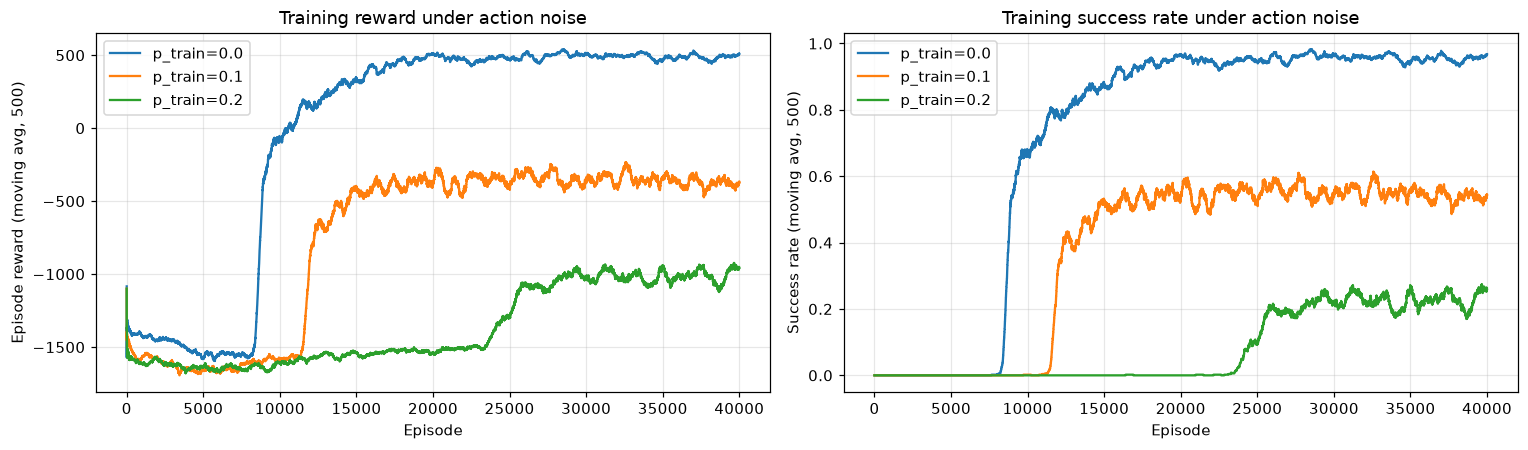

In [16]:
noise_levels = [0.0, 0.1, 0.2]
NOISE_KW = dict(num_episodes=40000, epsilon=0.5, alpha=0.3, gamma=0.99,
                epsilon_decay=0.9998, epsilon_min=0.01, seed=0)
trained_agents = {}
training_rewards = {}

for p_train in noise_levels:
    t0 = time.time()
    env = CliffBoxGridWorld()
    noisy_agent = RLAgent(env, noise_aware=True, **NOISE_KW)
    rewards_p = noisy_agent.learn(action_noise=p_train)
    trained_agents[p_train] = noisy_agent
    training_rewards[p_train] = rewards_p
    s = np.array(noisy_agent.successes)
    print(f"p_train={p_train}: {time.time()-t0:.0f}s | first success: {int(np.argmax(s)) if s.any() else None}"
          f" | train success (last 2000): {s[-2000:].mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for p_train in noise_levels:
    axes[0].plot(moving_average(training_rewards[p_train], 500), label=f"p_train={p_train}")
    axes[1].plot(moving_average(trained_agents[p_train].successes, 500), label=f"p_train={p_train}")
axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Episode reward (moving avg, 500)")
axes[0].set_title("Training reward under action noise"); axes[0].legend()
axes[1].set_xlabel("Episode"); axes[1].set_ylabel("Success rate (moving avg, 500)")
axes[1].set_title("Training success rate under action noise"); axes[1].legend()
plt.tight_layout(); plt.show()

### Evaluation under action noise

Rows: p_train = [0.0, 0.1, 0.2]
Columns: p_test = [0.0, 0.1, 0.2]
Success rate:
[[1.    0.458 0.154]
 [1.    0.574 0.256]
 [1.    0.546 0.23 ]]
Average episode return:
[[  577.   -478.  -1078.2]
 [  569.   -301.2  -960.8]
 [  573.   -351.4 -1005.5]]


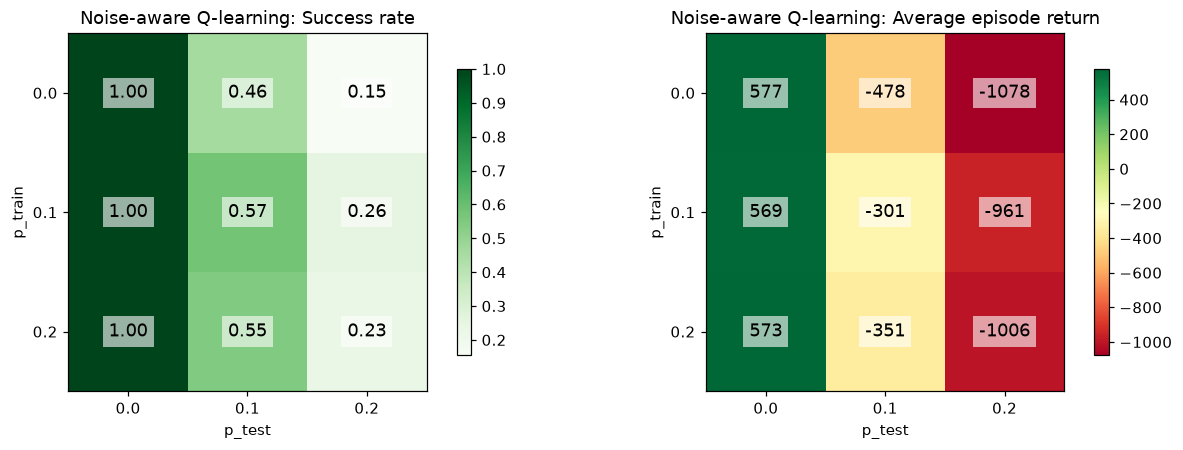

In [17]:
def evaluate(agent, p_test, total_run=100):
    env = CliffBoxGridWorld()
    success = 0
    episode_returns = []

    for _ in range(total_run):
        state = env.reset()
        done = False
        rewards = []

        while not done:
            action = agent.act(state, is_training=False)          # no exploration
            executed = apply_action_noise(action, p_test)          # keep only the test-time action noise
            next_state, reward, done, info = env.step(executed)
            state = next_state
            rewards.append(reward)

        if all(env.box_pos == env.goal_pos):
            success += 1
        episode_returns.append(sum(rewards))

    return success / total_run, np.mean(episode_returns)


def plot_matrices(success_rate, average_return, title_prefix=''):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, M, title, fmt, cmap in [(axes[0], success_rate, 'Success rate', '{:.2f}', 'Greens'),
                                    (axes[1], average_return, 'Average episode return', '{:.0f}', 'RdYlGn')]:
        im = ax.imshow(M, cmap=cmap)
        for i in range(3):
            for j in range(3):
                ax.text(j, i, fmt.format(M[i, j]), ha='center', va='center', fontsize=12,
                        color='black', bbox=dict(fc='white', alpha=0.6, ec='none'))
        ax.set_xticks(range(3)); ax.set_xticklabels(noise_levels); ax.set_xlabel('p_test')
        ax.set_yticks(range(3)); ax.set_yticklabels(noise_levels); ax.set_ylabel('p_train')
        ax.set_title(f'{title_prefix}{title}'); ax.grid(False)
        fig.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout(); plt.show()


np.random.seed(123)
success_rate = np.zeros((3, 3))
average_return = np.zeros((3, 3))

for i, p_train in enumerate(noise_levels):
    for j, p_test in enumerate(noise_levels):
        success_rate[i, j], average_return[i, j] = evaluate(
            trained_agents[p_train], p_test, total_run=500
        )

print("Rows: p_train =", noise_levels)
print("Columns: p_test =", noise_levels)
print("Success rate:")
print(success_rate)
print("Average episode return:")
print(np.round(average_return, 1))
plot_matrices(success_rate, average_return, 'Noise-aware Q-learning: ')

### Ablation: vanilla Q-learning under action noise

Same hyper-parameters, budget and seed, but the update credits the *selected* action (`noise_aware=False`). The $p_{train}=0$ agent is unchanged, because both rules are identical without noise.

vanilla p_train=0.1: 212s | first success: 27263 | train success (last 2000): 0.344
vanilla p_train=0.2: 120s | first success: None | train success (last 2000): 0.000
Vanilla Q-learning success rate:
[[1.    0.458 0.154]
 [1.    0.396 0.124]
 [0.    0.    0.   ]]
Vanilla Q-learning average return:
[[  577.   -478.  -1078.2]
 [  573.   -594.7 -1127.2]
 [-1350.  -1430.1 -1306.1]]


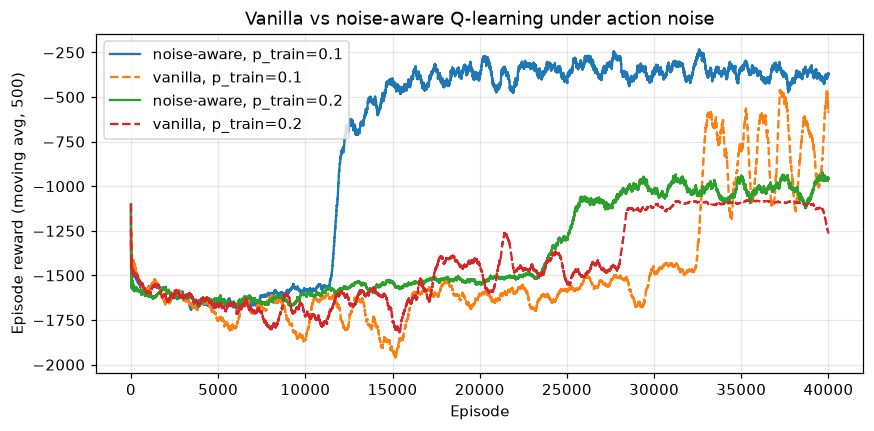

In [18]:
vanilla_agents = {0.0: trained_agents[0.0]}
vanilla_rewards = {0.0: training_rewards[0.0]}
for p_train in [0.1, 0.2]:
    t0 = time.time()
    env = CliffBoxGridWorld()
    a = RLAgent(env, noise_aware=False, **NOISE_KW)
    vanilla_rewards[p_train] = a.learn(action_noise=p_train)
    vanilla_agents[p_train] = a
    s = np.array(a.successes)
    print(f"vanilla p_train={p_train}: {time.time()-t0:.0f}s | first success: {int(np.argmax(s)) if s.any() else None}"
          f" | train success (last 2000): {s[-2000:].mean():.3f}")

np.random.seed(123)
v_success = np.zeros((3, 3)); v_return = np.zeros((3, 3))
for i, p_train in enumerate(noise_levels):
    for j, p_test in enumerate(noise_levels):
        v_success[i, j], v_return[i, j] = evaluate(vanilla_agents[p_train], p_test, total_run=500)
print("Vanilla Q-learning success rate:"); print(v_success)
print("Vanilla Q-learning average return:"); print(np.round(v_return, 1))

plt.figure(figsize=(9, 4))
for p_train, ls in [(0.1, '-'), (0.2, '-')]:
    plt.plot(moving_average(training_rewards[p_train], 500), ls, label=f'noise-aware, p_train={p_train}')
    plt.plot(moving_average(vanilla_rewards[p_train], 500), '--', label=f'vanilla, p_train={p_train}')
plt.xlabel('Episode'); plt.ylabel('Episode reward (moving avg, 500)')
plt.title('Vanilla vs noise-aware Q-learning under action noise'); plt.legend(); plt.show()

### Reference: optimal policies by value iteration

The environment is deterministic and only 7056 × 4 state-action pairs exist, so we can record the exact transition of every (state, action) by calling `step()` from that state. Value iteration on the noisy model (γ = 0.99) then gives the best achievable policy for each noise level. This is used **only** as a ceiling to judge how close the learned agents get; the agents themselves are model-free.

In [19]:
def build_model():
    # Record next state, reward and terminal flag for every (state, action) using the unmodified step().
    H, W = CliffBoxGridWorld.world_height, CliffBoxGridWorld.world_width
    NS = np.zeros((H, W, H, W, 4, 4), dtype=int); RR = np.zeros((H, W, H, W, 4)); TT = np.zeros((H, W, H, W, 4), bool)
    env = CliffBoxGridWorld()
    for s in np.ndindex(H, W, H, W):
        for a in range(4):
            env.reset()
            env.agent_pos, env.box_pos = np.array(s[:2]), np.array(s[2:])
            s2, r, _, _ = env.step(a + 1)
            NS[s + (a,)] = s2; RR[s + (a,)] = r; TT[s + (a,)] = reached_goal(env) or fell_off_cliff(env)
    return NS, RR, TT

def value_iteration(model, p, gamma=0.99, tol=1e-6):
    NS, RR, TT = model
    V = np.zeros(NS.shape[:4])
    while True:
        Qd = RR + gamma * np.where(TT, 0.0, V[NS[..., 0], NS[..., 1], NS[..., 2], NS[..., 3]])
        Qp = (1 - p) * Qd + (p / 3) * (Qd.sum(-1, keepdims=True) - Qd)   # expected value under action noise
        V_new = Qp.max(-1)
        if np.abs(V_new - V).max() < tol:
            return Qp
        V = V_new

class TablePolicy:
    # Wraps a Q array so it can be used with evaluate().
    def __init__(self, Q): self.Q = Q
    def act(self, state, is_training=False):
        q = self.Q[state]; best = np.flatnonzero(q == q.max())
        return int(best[np.random.randint(len(best))]) + 1

t0 = time.time()
model = build_model()
np.random.seed(123)
opt_success = np.zeros((3, 3)); opt_return = np.zeros((3, 3))
for i, p in enumerate(noise_levels):
    pol = TablePolicy(value_iteration(model, p))
    for j, p_test in enumerate(noise_levels):
        opt_success[i, j], opt_return[i, j] = evaluate(pol, p_test, total_run=500)
print(f"({time.time()-t0:.0f}s)  Rows: policy optimal for p = {noise_levels}; columns: p_test")
print("Optimal-policy success rate:"); print(opt_success)
print("Optimal-policy average return:"); print(np.round(opt_return, 1))

(24s)  Rows: policy optimal for p = [0.0, 0.1, 0.2]; columns: p_test
Optimal-policy success rate:
[[1.    0.49  0.198]
 [1.    0.584 0.262]
 [1.    0.638 0.248]]
Optimal-policy average return:
[[ 577.  -414.  -978.9]
 [ 569.  -281.  -953.5]
 [ 569.  -186.3 -988.4]]


In [20]:
# Side-by-side summary: how close each method gets to the optimum when p_train == p_test
rows = []
for k, p in enumerate(noise_levels):
    rows.append((p, opt_success[k, k], success_rate[k, k], v_success[k, k]))
print(f"{'p':>5} | {'optimal (VI)':>12} | {'noise-aware QL':>14} | {'vanilla QL':>10}")
for p, o, n, v in rows:
    print(f"{p:>5} | {o:>12.2f} | {n:>14.2f} | {v:>10.2f}")

    p | optimal (VI) | noise-aware QL | vanilla QL
  0.0 |         1.00 |           1.00 |       1.00
  0.1 |         0.58 |           0.57 |       0.40
  0.2 |         0.25 |           0.23 |       0.00


### Discussion: how action noise affects learning and robustness

**1. Noise makes learning slower and the task fundamentally harder.**
* With identical hyper-parameters, the goal is first reached at episode ~7.6k ($p=0$), ~9.7k ($p=0.1$) and ~16.4k ($p=0.2$).
* Training success converges to ~96%, ~54% and ~23% respectively.
* The low numbers under noise are **not a learning failure**. Value iteration shows that even the *optimal* policy only succeeds ~58% of the time at $p=0.1$ and ~25% at $p=0.2$.
* The reason is the length of the solution: it needs ~40 steps, many of them next to a cliff. With $p=0.2$, each step executes a different action 20% of the time, and a wrong push next to a cliff ends the episode.
* Noise-aware Q-learning gets within about 1–2 percentage points of the optimum at every noise level.

**2. The update rule matters a lot under noise.**
* Vanilla Q-learning credits the *selected* action with the outcome of whatever action was actually executed. Every $(s,a)$ next to a cliff therefore occasionally receives a −1000 target, so its value estimate is very noisy.
* With the same budget, vanilla Q-learning reached only 40% success at $p=0.1$ (first success after ~27k episodes). It **never** reached the goal at $p=0.2$ and settled on the early-suicide policy (return ≈ −1300).
* Learning $Q_{det}$ for the executed action, and acting on the noise-expected value, removes that variance while keeping the same fixed point.

**3. Training with moderate noise improves robustness (the off-diagonal entries).**
* At $p_{test}=0.1$, the noise-free agent ($p_{train}=0$) succeeds 46% of the time. The $p_{train}=0.1$ agent succeeds 57%, a +11-point improvement, and its average return improves from −478 to −301.
* At $p_{test}=0.2$, success improves from 15% to 26% (+11 points) for the $p_{train}=0.1$ agent, and to 23% for the $p_{train}=0.2$ agent.
* All noise-trained agents still succeed 100% of the time at $p_{test}=0$. Robustness costs only 4–8 points of return (569–573 vs 577), from a slightly longer or safer route.
* The trajectory plot above shows *why*. The $p_{train}=0.2$ agent pushes the box down **column 1** instead of column 2, keeping it one cell further from the column-3 cliff, and it keeps a larger margin from cliffs elsewhere. The noise-free agent takes the shortest path along the cliff edge, which is optimal without noise but fragile with it.

**4. Moderate noise is the sweet spot.** In our results, $p_{train}=0.1$ was as robust as, or slightly more robust than, $p_{train}=0.2$, even at $p_{test}=0.2$. Training at $p=0.2$ costs more than twice as many episodes to find the goal and gives a noisier value estimate for the same budget. A moderate amount of training noise teaches the agent the risk of cliffs without making the learning problem itself much harder. With 500 evaluation episodes, the standard error of a success rate around 0.25 is about ±0.02, so the 0.1-vs-0.2 differences are small. The improvement over $p_{train}=0$ is clearly larger than this.

Policy learned by the $p_{train}=0.2$ agent compared with the noise-free agent, for the initial box position. Look for detours away from cliffs.

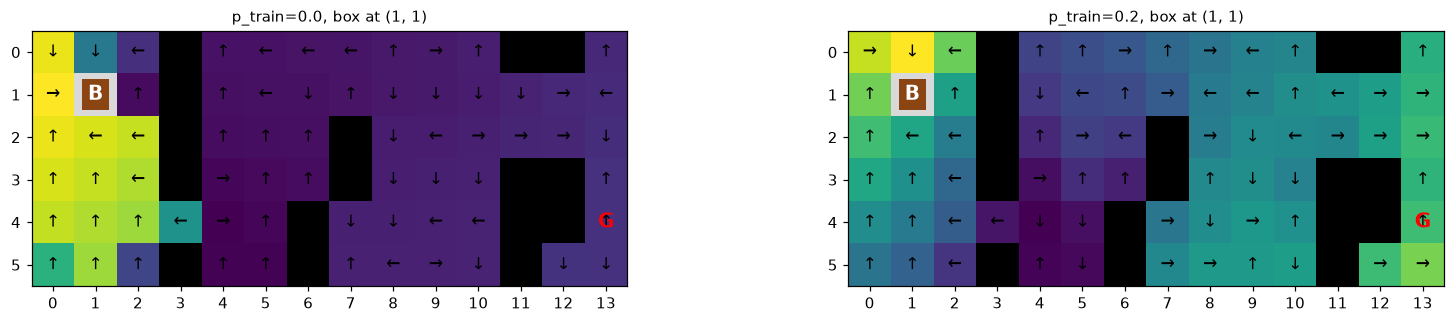

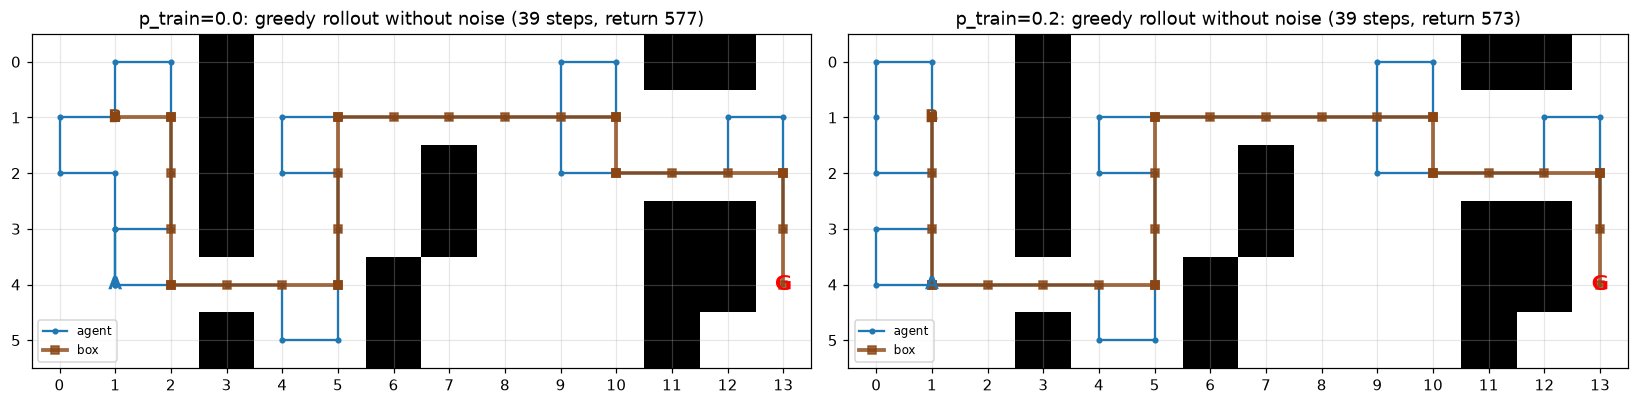

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3))
for ax, p in zip(axes, [0.0, 0.2]):
    plot_policy_for_box(trained_agents[p], (1, 1), ax, title=f'p_train={p}, box at (1, 1)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, p in zip(axes, [0.0, 0.2]):
    st, ac, rt, ok = greedy_rollout(trained_agents[p])
    plot_trajectory(st, ax, f'p_train={p}: greedy rollout without noise ({len(ac)} steps, return {rt})')
plt.tight_layout(); plt.show()

## 6. Bonus 1: comparison of exploration strategies

All runs use the original dense reward, Q-learning with α = 0.5, γ = 0.99, Q initialised to 0, 10,000 episodes and 3 seeds. Strategies:

| Strategy | Rule |
|---|---|
| No exploration (greedy, Q₀ = 0) | always $\arg\max_a Q$ |
| No exploration, pessimistic Q₀ = −1000 | same, but Q starts *below* every true return |
| ε-greedy, constant ε = 0.1 | template default |
| ε-greedy, decaying | ε = 0.2 × 0.9995ᵉᵖ, floor 0.01 |
| UCB | $\arg\max_a Q(s,a) + c\sqrt{\ln N(s)/N(s,a)}$, c = 20; every action tried once first |
| Boltzmann (softmax) | $\pi(a\mid s) \propto \exp(Q(s,a)/\tau)$, τ = 20 |

Metrics: first successful episode (sample efficiency), training success rate over the last 1000 episodes (cost of exploring), and greedy success after training (quality of the final policy).

In [22]:
STRATEGIES = {
    'No exploration (Q0=0)':       dict(exploration='greedy'),
    'No exploration (Q0=-1000)':   dict(exploration='greedy', q_init=-1000.0),
    'ε-greedy const 0.1':          dict(exploration='epsilon_greedy', epsilon=0.1, epsilon_decay=1.0, epsilon_min=0.1),
    'ε-greedy decaying':           dict(exploration='epsilon_greedy', epsilon=0.2, epsilon_decay=0.9995, epsilon_min=0.01),
    'UCB (c=20)':                  dict(exploration='ucb', ucb_c=20.0),
    'Boltzmann (τ=20)':            dict(exploration='boltzmann', temperature=20.0),
}
SEEDS = [0, 1, 2]
explore_results = {}
t0 = time.time()
for name, kw in STRATEGIES.items():
    runs = []
    for seed in SEEDS:
        env = CliffBoxGridWorld()
        a = RLAgent(env, num_episodes=10000, alpha=0.5, gamma=0.99, seed=seed, **kw)
        r = a.learn()
        s = np.array(a.successes)
        np.random.seed(1000 + seed)
        greedy_sr, greedy_ret = evaluate(a, 0.0, total_run=100)
        runs.append(dict(rewards=np.array(r), successes=s,
                         first=int(np.argmax(s)) if s.any() else np.nan,
                         last=s[-1000:].mean(), greedy=greedy_sr, greedy_ret=greedy_ret,
                         steps=int(np.sum(a.episode_lengths))))
    explore_results[name] = runs
    print(f"{name:<28} done ({time.time()-t0:.0f}s)")

print()
print(f"{'Strategy':<28}|{'first success (mean±sd)':>25} |{'train success last 1k':>22} |{'greedy success':>15} |{'greedy return':>14}")
for name, runs in explore_results.items():
    f = np.array([r['first'] for r in runs], dtype=float)
    first_txt = 'never' if np.isnan(f).all() else f"{np.nanmean(f):.0f} ± {np.nanstd(f):.0f}" + ('' if not np.isnan(f).any() else ' (some never)')
    print(f"{name:<28}|{first_txt:>25} |{np.mean([r['last'] for r in runs]):>22.3f} |"
          f"{np.mean([r['greedy'] for r in runs]):>15.2f} |{np.mean([r['greedy_ret'] for r in runs]):>14.1f}")

No exploration (Q0=0)        done (125s)
No exploration (Q0=-1000)    done (133s)
ε-greedy const 0.1           done (258s)
ε-greedy decaying            done (387s)
UCB (c=20)                   done (541s)
Boltzmann (τ=20)             done (984s)

Strategy                    |  first success (mean±sd) | train success last 1k | greedy success | greedy return
No exploration (Q0=0)       |                1742 ± 65 |                 1.000 |           1.00 |         577.0
No exploration (Q0=-1000)   |                    never |                 0.000 |           0.00 |       -1057.0
ε-greedy const 0.1          |               3052 ± 121 |                 0.597 |           1.00 |         577.0
ε-greedy decaying           |                2923 ± 59 |                 0.949 |           1.00 |         577.0
UCB (c=20)                  |                 1755 ± 7 |                 1.000 |           1.00 |         575.7
Boltzmann (τ=20)            |               8436 ± 776 |                 0.104 | 

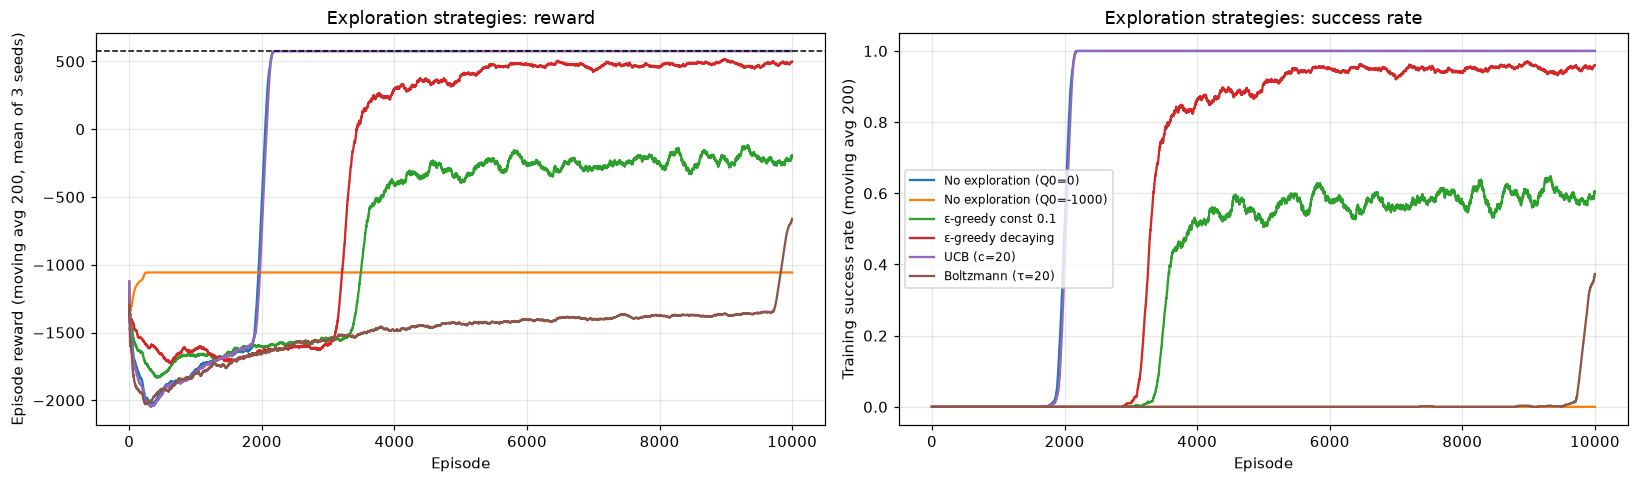

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, runs in explore_results.items():
    sr = np.mean([moving_average(r['successes'], 200) for r in runs], axis=0)
    rw = np.mean([moving_average(r['rewards'], 200) for r in runs], axis=0)
    axes[0].plot(rw, label=name); axes[1].plot(sr, label=name)
axes[0].set_xlabel('Episode'); axes[0].set_ylabel('Episode reward (moving avg 200, mean of 3 seeds)')
axes[0].set_title('Exploration strategies: reward'); axes[0].axhline(577, color='k', ls='--', lw=1)
axes[1].set_xlabel('Episode'); axes[1].set_ylabel('Training success rate (moving avg 200)')
axes[1].set_title('Exploration strategies: success rate'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Analysis of exploration strategies

* **No exploration works best here, because Q₀ = 0 is optimistic.** Every real step costs about −15, so any action already tried has $Q<0$ while untried actions stay at 0. Greedy action selection therefore always prefers untried actions, a deterministic, *directed* exploration. It found the goal first (~1740 episodes) and then never made exploratory mistakes (100% training success).
* **The same greedy agent with pessimistic Q₀ = −1000 never finds the goal.** It immediately learns that jumping off a cliff (≈ −1016) is better than wandering (≈ −1500 per episode) and locks into the early-suicide policy. This confirms the reward trap described in Section 1, and shows that the success of "no exploration" comes entirely from optimistic initialisation.
* **UCB** matches the greedy agent's speed (~1755 episodes, lowest variance across seeds). The count bonus adds directed exploration on top of the optimism, but there is little left to gain in a deterministic environment where optimism already explores systematically.
* **ε-greedy** spends exploration *undirected*: random actions are rarely the long, coordinated sequences needed to move the box, so the goal is found later (~2900–3050 episodes). With constant ε = 0.1, the random actions keep causing cliff falls, so training success stays at ~60%. Decaying ε fixes the second problem (95%).
* **Boltzmann (τ = 20)** is the slowest (~8400 episodes). Q-values differ by hundreds near cliffs, so the softmax is almost greedy there but nearly uniform among similar actions elsewhere. This scale sensitivity makes it hard to tune for this reward range.
* After training, all methods except pessimistic greedy reach a 100%-success greedy policy with near-optimal return (575.7–577). The strategies differ in **sample efficiency** and in **performance during training**, not in the final policy.

**Conclusion:** for a deterministic tabular task with negative step rewards, directed exploration (optimism or UCB) beats undirected random exploration by about 1.7× in sample efficiency. A non-exploring agent is only safe when its initial values are optimistic.

## 7. Bonus 2: sparse reward

The agent now **only** receives +1000 when the box reaches the goal, and 0 otherwise (also 0 when falling off a cliff, which still ends the episode). The environment is unchanged; the agent replaces the reward signal it learns from (`sparse_reward=True`). For comparability, the plotted episode returns are still the original dense rewards.

**Why this is hard.** Reaching the goal needs a precise sequence of about 30+ moves that pushes the box through narrow gaps between cliffs. Until the goal is reached once, every Q-value stays at its initial value, so ε-greedy behaves like a random walk, and a random walk essentially never solves this puzzle.

**Our idea: optimism in the face of uncertainty.** Initialise every Q-value to the maximum possible return (Q₀ = 1000) and act greedily. Any state-action that has not been tried keeps the optimistic value 1000. Tried actions that lead to cliffs drop to 0 (true terminal), and actions that loop drop by a factor of γ each time. The greedy agent is therefore *systematically drawn to the least-explored parts of the state space*, in the spirit of R-max-style directed exploration. Once the goal is found, the +1000 propagates back through the optimistic values. Discounting (γ = 0.99) makes shorter solutions worth more, so the agent also learns an efficient path even though the reward says nothing about step costs.

Methods compared (15,000 episodes, 2 seeds each):
1. ε-greedy (decaying), Q₀ = 0: the naive baseline.
2. ε-greedy + count-based intrinsic bonus $\beta/\sqrt{N(s')}$, β = 100 (a common exploration-bonus approach).
3. **Optimistic initialisation Q₀ = 1000 + greedy action selection** (ours).

In [24]:
SPARSE_METHODS = {
    'ε-greedy, Q0=0':                     dict(exploration='epsilon_greedy', epsilon=0.2, epsilon_decay=0.9995),
    'ε-greedy + count bonus (β=100)':     dict(exploration='epsilon_greedy', epsilon=0.2, epsilon_decay=0.9995, count_bonus=100.0),
    'Optimistic Q0=1000 + greedy (ours)': dict(exploration='greedy', q_init=1000.0),
}
sparse_results = {}
sparse_agents = {}
t0 = time.time()
for name, kw in SPARSE_METHODS.items():
    runs = []
    for seed in [0, 1]:
        env = CliffBoxGridWorld()
        a = RLAgent(env, num_episodes=15000, alpha=0.5, gamma=0.99, sparse_reward=True, seed=seed, **kw)
        r = a.learn()
        s = np.array(a.successes)
        np.random.seed(2000 + seed)
        sr, ret = evaluate(a, 0.0, total_run=100)
        states_vis = sum(1 for v in a.state_visits.values() if v > 0)
        runs.append(dict(rewards=np.array(r), successes=s, first=int(np.argmax(s)) if s.any() else np.nan,
                         last=s[-1000:].mean(), greedy=sr, greedy_ret=ret, visited=states_vis))
        sparse_agents[(name, seed)] = a
    sparse_results[name] = runs
    print(f"{name:<36} done ({time.time()-t0:.0f}s)")

print()
print(f"{'Method':<36}|{'first success':>16} |{'train success last 1k':>22} |{'greedy success':>15} |{'greedy return (dense)':>22} |{'states visited':>15}")
for name, runs in sparse_results.items():
    f = [r['first'] for r in runs]
    print(f"{name:<36}|{str([('never' if np.isnan(x) else int(x)) for x in f]):>16} |{np.mean([r['last'] for r in runs]):>22.3f} |"
          f"{np.mean([r['greedy'] for r in runs]):>15.2f} |{np.mean([r['greedy_ret'] for r in runs]):>22.1f} |{np.mean([r['visited'] for r in runs]):>15.0f}")

ε-greedy, Q0=0                       done (55s)
ε-greedy + count bonus (β=100)       done (240s)
Optimistic Q0=1000 + greedy (ours)   done (298s)

Method                              |   first success | train success last 1k | greedy success | greedy return (dense) | states visited
ε-greedy, Q0=0                      |['never', 'never'] |                 0.000 |           0.00 |               -1408.4 |            286
ε-greedy + count bonus (β=100)      |['never', 'never'] |                 0.000 |           0.00 |               -1972.0 |            492
Optimistic Q0=1000 + greedy (ours)  |    [3155, 3127] |                 1.000 |           1.00 |                 569.2 |           3260


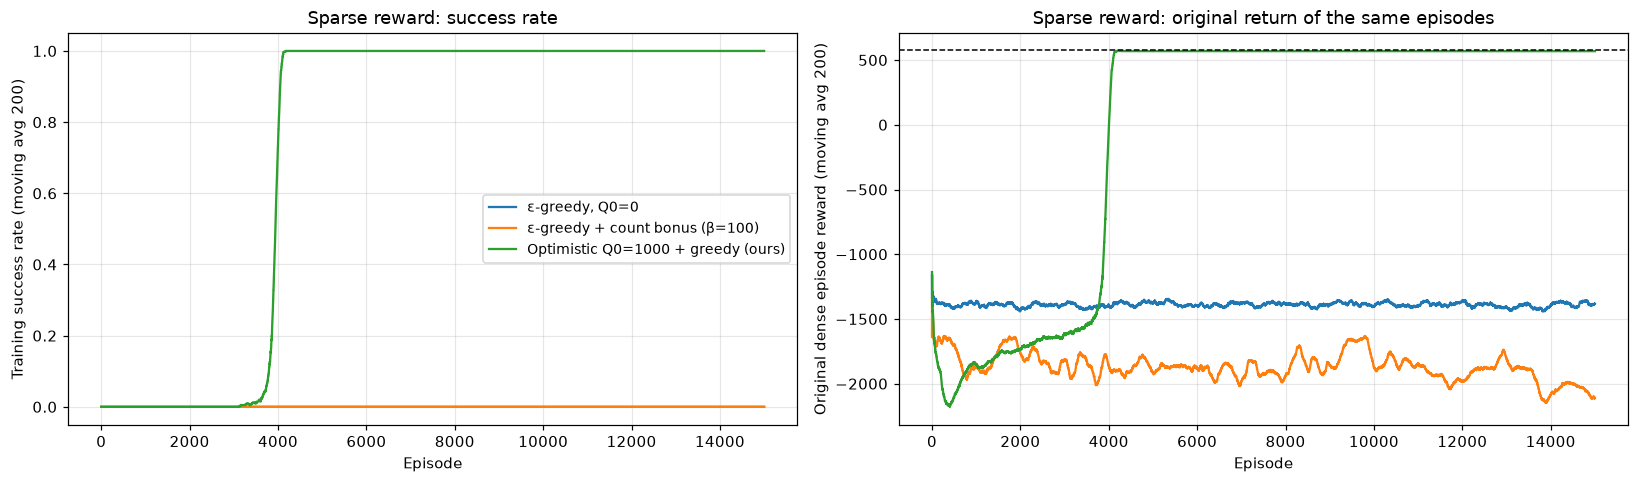

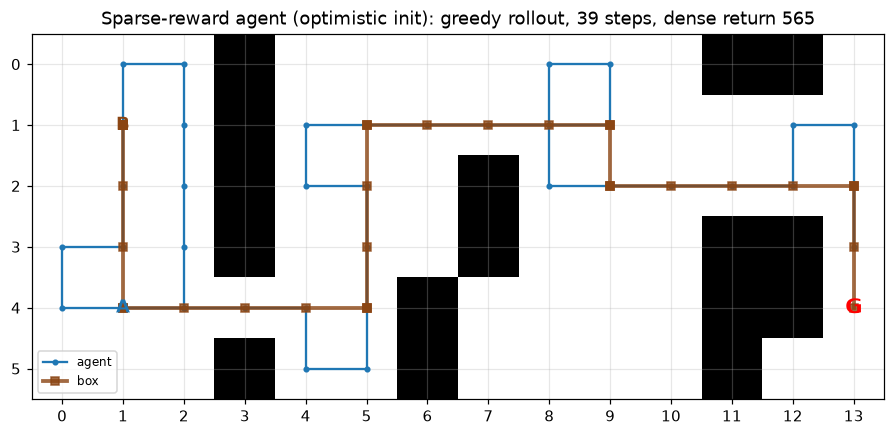

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, runs in sparse_results.items():
    axes[0].plot(np.mean([moving_average(r['successes'], 200) for r in runs], axis=0), label=name)
    axes[1].plot(np.mean([moving_average(r['rewards'], 200) for r in runs], axis=0), label=name)
axes[0].set_xlabel('Episode'); axes[0].set_ylabel('Training success rate (moving avg 200)')
axes[0].set_title('Sparse reward: success rate'); axes[0].legend(fontsize=9)
axes[1].set_xlabel('Episode'); axes[1].set_ylabel('Original dense episode reward (moving avg 200)')
axes[1].set_title('Sparse reward: original return of the same episodes'); axes[1].axhline(577, color='k', ls='--', lw=1)
plt.tight_layout(); plt.show()

opt_sparse = sparse_agents[('Optimistic Q0=1000 + greedy (ours)', 0)]
st, ac, rt, ok = greedy_rollout(opt_sparse)
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_trajectory(st, ax, f'Sparse-reward agent (optimistic init): greedy rollout, {len(ac)} steps, dense return {rt}')
plt.show()

### Analysis of the sparse-reward setting

* **ε-greedy with Q₀ = 0 never reaches the goal** in 15,000 episodes on either seed. Without any reward, all Q-values stay at 0 and the agent performs a random walk. It visits only ~290 distinct states, because random walks keep falling into cliffs early.
* **The count-based bonus (β = 100) roughly doubles the number of visited states (~490), but still never reaches the goal.** The bonus is about novel *(agent, box)* combinations, and most of them come from the agent walking around without moving the box. Moving the box far requires long coordinated sequences that a state-count bonus does not reward strongly enough, and episodes keep ending in cliffs.
* **Optimistic initialisation (Q₀ = 1000, ours) solves the task on both seeds**, finding the goal after ~3,100–3,200 episodes. It then reaches 100% training and greedy success, and visits ~3,260 distinct states (11× more than ε-greedy).
  * Every untried action promises the maximum return, so the agent systematically exhausts each region (including box-moving actions) before moving on.
  * Cliff actions are quickly ruled out because their target is 0.
* Even though the sparse reward contains no step penalty, discounting makes the agent prefer short solutions. Its greedy policy scores **~569 under the original dense reward** (the optimum is 577). The sparse-reward agent therefore learns a near-optimal policy for the original task.

This is the same mechanism that made "no exploration" work in Bonus 1, and it is the tabular version of the *optimism in the face of uncertainty* principle behind R-max and UCB-style algorithms. A hierarchical alternative (e.g., options for "walk to the push position" and "push the box once", as in option-critic) would mainly help larger maps where a table cannot be explored exhaustively. For a 7k-state table, directed optimistic exploration is the simpler and fully sufficient solution.

## 8. Summary

| Experiment | Result |
|---|---|
| Q-learning, dense reward | Optimal greedy policy (39 steps, return 577, 100% success) after ~3k episodes; ~95% training success |
| Hyper-parameter ablation | Decaying ε + α = 0.5: goal found 2.3× faster than template defaults; training success 95% vs 58% |
| Robustness: noise-aware QL vs optimum | 1.00 / 0.57 / 0.23 vs value-iteration optimum 1.00 / 0.58 / 0.25 (matched train/test noise) |
| Robustness: train with noise | $p_{train}=0.1$ improves success at $p_{test}=0.1$ from 0.46 → 0.57 and at $p_{test}=0.2$ from 0.15 → 0.26, with no loss at $p_{test}=0$ |
| Vanilla QL under noise | 0.40 at $p=0.1$; never solves $p=0.2$ (learns early suicide) |
| Bonus 1: exploration | Optimistic greedy ≈ UCB (~1750 episodes) > decaying ε-greedy (~2900) > const ε (~3050) > Boltzmann (~8400); pessimistic greedy never succeeds |
| Bonus 2: sparse reward | Optimistic initialisation solves it on all seeds (dense return 569); ε-greedy and count bonus never reach the goal |

**Modifications to the provided code (game setting untouched):**
1. NumPy 2 compatibility alias for `np.chararray` (only needed to render).
2. Success is measured as "box on goal", not "return > 0".
3. Timeouts are treated as truncation in the TD target.
4. The interactive input cell is behind a `MANUAL_PLAY` flag, so the notebook runs end to end.
5. Action noise and the sparse reward are applied in the agent/training loop, never inside `step()`.